In [1]:
# ================================================================================
# SETUP: minimal config needed to load the trained model and run Phase 4 eval
# (No training here - this just recreates the preprocessing pipeline + loads
# your already-trained .keras checkpoint.)
# ================================================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from PIL import Image, ImageFilter
from tensorflow.keras.utils import image_dataset_from_directory
from tensorflow.keras.applications.vgg16 import preprocess_input as vgg16_preprocess
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess
from tensorflow.keras.applications.inception_v3 import preprocess_input as inception_preprocess

# --------------------------------------------------------------------------------
# EDIT THESE 2 PATHS
# --------------------------------------------------------------------------------
# 1. FER2013 dataset path - needed for the TRUE test_dir (Phase 4 evaluates on this).
#    Add the FER2013 dataset as input to this new notebook too, then check the
#    exact path in the left panel and update below.
KAGGLE_INPUT_PATH = "/kaggle/input/datasets/msambare/fer2013"   # <-- confirm this matches your setup

# 2. Path to your uploaded finetuned model file (check left panel after adding it as input)
# 2. Path to your ORIGINAL finetuned model (66.22% accuracy) - NOT the "robust"
#    checkpoint, which regressed to 55.21% due to a validation-leakage bug in
#    Phase 6 (being fixed separately). Check left panel after adding it as input.
MODEL_PATH = "/kaggle/input/models/akruti850/fusion-model/pytorch/default/1/final_multi_backbone_fusion_finetuned.keras"  # <-- confirm this matches your setup

# --------------------------------------------------------------------------------
# Fixed config (matches your original training notebook - don't need to change)
# --------------------------------------------------------------------------------
test_dir = os.path.join(KAGGLE_INPUT_PATH, "test")
IMG_SIZE = (224, 224)
NUM_CLASSES = 7
BATCH_SIZE = 32
class_names = ["Angry", "Disgust", "Fear", "Happy", "Neutral", "Sad", "Surprise"]  # FIXED: matches alphabetical folder order TensorFlow actually uses

print("test_dir:", test_dir, "| exists:", os.path.exists(test_dir))
print("Classes found:", os.listdir(test_dir) if os.path.exists(test_dir) else "PATH NOT FOUND - fix KAGGLE_INPUT_PATH above")

# --------------------------------------------------------------------------------
# Load the trained model directly - no training needed
# --------------------------------------------------------------------------------
multi_model = tf.keras.models.load_model(MODEL_PATH)
print(f"\nModel loaded successfully from {MODEL_PATH}")
multi_model.summary()


test_dir: /kaggle/input/datasets/msambare/fer2013/test | exists: True
Classes found: ['surprise', 'fear', 'angry', 'neutral', 'sad', 'disgust', 'happy']


I0000 00:00:1789840037.307778      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1789840037.311012      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5



Model loaded successfully from /kaggle/input/models/akruti850/fusion-model/pytorch/default/1/final_multi_backbone_fusion_finetuned.keras


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_vgg16         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_resnet50      │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_inceptionv3   │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vgg16_backbone      │ (None, 7, 7, 512) │ 14,714,688 │ input_vgg16[0][0] │
│ (Functional)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet50_backbone   │ (None, 7, 7,      │ 23,587,712 │ input_resnet50[0… │
│ (Functional)        │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inceptionv3_backbo… │ (None, 5, 5,      │ 21,802,784 │ input_inceptionv… │
│ (Functional)        │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vgg_gap             │ (None, 512)       │          0 │ vgg16_backbone[0… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet_gap          │ (None, 2048)      │          0 │ resnet50_backbon… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inception_gap       │ (None, 2048)      │          0 │ inceptionv3_back… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fusion_concat       │ (None, 4608)      │          0 │ vgg_gap[0][0],    │
│ (Concatenate)       │                   │            │ resnet_gap[0][0], │
│                     │                   │            │ inception_gap[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 512)       │  2,359,808 │ fusion_concat[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 512)       │      2,048 │ dense[0][0]       │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 512)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 256)       │    131,328 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256)       │      1,024 │ dense_1[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 256)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 7)         │      1,799 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 165,344,503 (630.74 MB)

 Trainable params: 51,371,655 (195.97 MB)

 Non-trainable params: 11,229,536 (42.84 MB)

 Optimizer params: 102,743,312 (391.93 MB)


A. ADVANCED STATISTICAL EVALUATION (on true held-out test set)
Found 7178 files belonging to 7 classes.


I0000 00:00:1789840082.408880      71 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.



--- Classification Report (TRUE test set) ---
              precision    recall  f1-score   support

       Angry     0.5688    0.5783    0.5735       958
     Disgust     0.5932    0.6306    0.6114       111
        Fear     0.5290    0.4453    0.4836      1024
       Happy     0.8434    0.8805    0.8616      1774
     Neutral     0.6288    0.6099    0.6192      1233
         Sad     0.5387    0.5413    0.5400      1247
    Surprise     0.7411    0.8231    0.7799       831

    accuracy                         0.6622      7178
   macro avg     0.6347    0.6441    0.6384      7178
weighted avg     0.6564    0.6622    0.6584      7178

--- Confusion Matrix ---


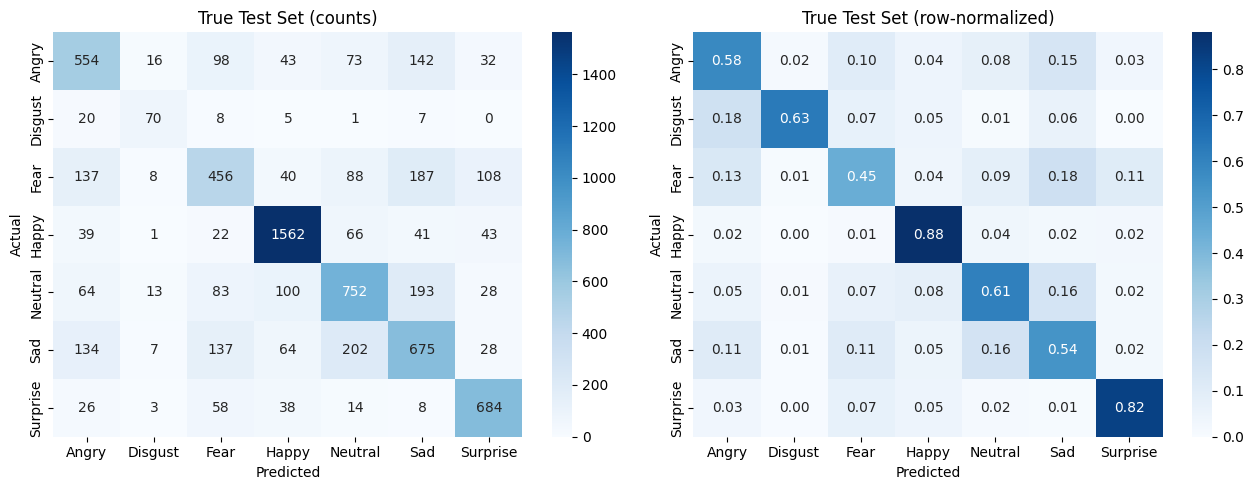


--- Bootstrap 95% Confidence Intervals (1000 resamples) ---
Accuracy : 66.22%  [95% CI: 65.12% - 67.30%]
Macro F1 : 63.80%  [95% CI: 62.32% - 65.28%]

--- Significance vs Majority-Class Baseline ---
Majority-class baseline (Happy): 24.71%
Model accuracy on true test set: 66.22%
-> Model is statistically better than majority-class guessing.

--- Error Analysis (with actual misclassified images) ---

Total test images: 7178 | Wrong: 2425 (33.8%)

Top 10 most confidently WRONG predictions:


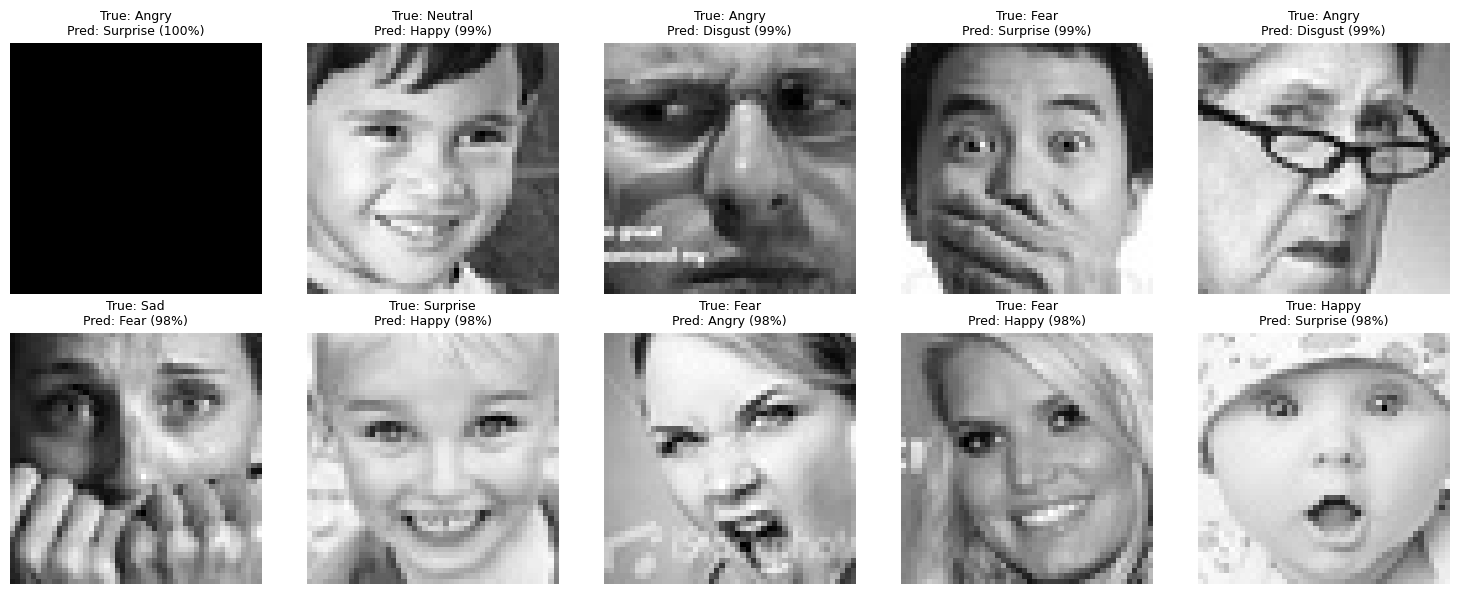


--- Per-class breakdown (which emotions confuse the model most) ---
   Class  Precision   Recall       F1  Support
    Fear   0.529002 0.445312 0.483563     1024
     Sad   0.538707 0.541299 0.540000     1247
   Angry   0.568789 0.578288 0.573499      958
 Disgust   0.593220 0.630631 0.611354      111
 Neutral   0.628763 0.609895 0.619185     1233
Surprise   0.741062 0.823105 0.779932      831
   Happy   0.843413 0.880496 0.861555     1774
(Lowest F1 rows above are your weakest emotion classes - FER2013's 'Disgust' usually ranks lowest since it has the fewest training images.)
Found 7178 files belonging to 7 classes.

B. REAL-WORLD / ROBUSTNESS TESTING (simulated production conditions)
clean (baseline)            :  70.0% accuracy (n=40)
low brightness (0.5x)       :  67.5% accuracy (n=40)
high brightness (1.6x)      :  35.0% accuracy (n=40)
gaussian noise              :  27.5% accuracy (n=40)
gaussian blur               :  12.5% accuracy (n=40)
occlusion (30% patch)       :  65.0% ac

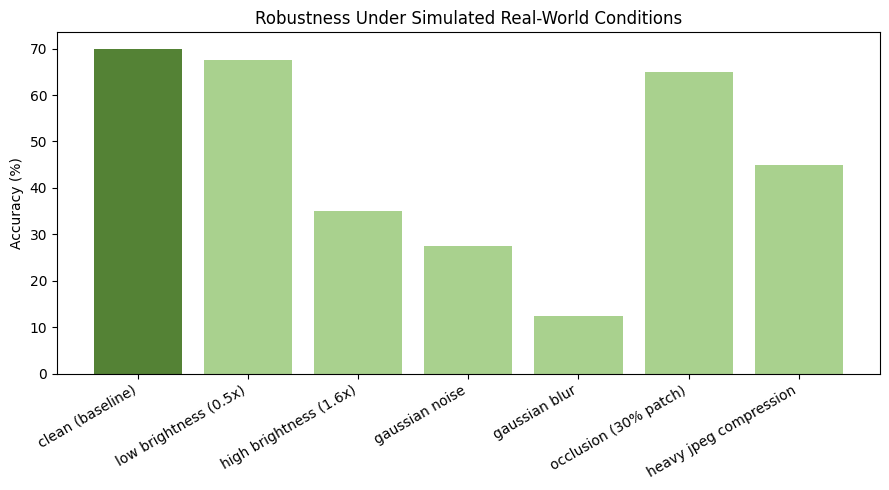


C. PIPELINE / CODE UNIT TESTS
[PASS] Resized image shape == (1, 224, 224, 3)
[PASS] Pixel values remain finite after preprocessing
[PASS] Model output is one of the 7 known classes
[PASS] Prediction confidence in [0, 1]
[PASS] Same input image produces identical prediction
[PASS] RGB-mode input image handled without crash
[PASS] Very small image (5x5) resized and predicted without crash
[PASS] All-black and all-white images handled without crash
[PASS] Prediction consistent whether run singly or in a batch

Unit test summary: 9 passed, 0 failed out of 9

D. PRODUCTION READINESS

--- Model Footprint ---
Total parameters     : 62,601,191
Trainable parameters : 51,371,655
Note: 3 full ImageNet backbones (VGG16+ResNet50+InceptionV3) is a large model for edge/mobile deployment - fine for server-side inference.

--- Latency Benchmark ---
Single-image latency over 30 runs:
  mean: 137.5 ms | p50: 136.7 ms | p95: 141.7 ms | p99: 149.0 ms

--- Example predict_api() call ---
{
  "image_path": "

In [2]:
"""
================================================================================
PHASE 4 (FACE MODEL): COMPREHENSIVE EVALUATION & TESTING
Model: Multi-Backbone Fusion (VGG16 + ResNet50 + InceptionV3), FER2013, 7 classes
================================================================================

Covers the same 4 pillars as the text-model evaluation:
  A. Advanced statistical evaluation   (TRUE held-out test set, confusion matrix,
                                         per-class metrics, bootstrap CI,
                                         significance vs baseline, error analysis
                                         with actual misclassified image previews)
  B. Real-world / robustness testing   (image-domain equivalent of sarcasm/negation:
                                         brightness/contrast shift, blur, occlusion,
                                         noise, JPEG compression, rotation)
  C. Pipeline / code testing           (unit tests for preprocessing, model I/O,
                                         determinism, batch consistency, corrupt input)
  D. Production readiness              (save/load, standalone predict_api(), latency
                                         benchmark, model footprint, logging)

--------------------------------------------------------------------------------
IMPORTANT FIX FIRST: use the REAL held-out test set, not the validation set
--------------------------------------------------------------------------------
Your original notebook never uses `test_dir` (the actual FER2013 test/ folder) -
final metrics were computed on `validation`, the same split used for
ModelCheckpoint model selection. That inflates reported performance slightly.
This script builds a genuine test pipeline from `test_dir` and evaluates on that.

PREREQUISITES
--------------
Run this AFTER your existing notebook cells, in the SAME kernel session (reuses:
multi_model, vgg16_preprocess, resnet_preprocess, inception_preprocess,
data_augmentation-free path, IMG_SIZE, NUM_CLASSES, class_names, test_dir,
BATCH_SIZE). If multi_model isn't in memory, Section D.1 shows how to reload
the saved .keras checkpoint.
================================================================================
"""

import os
import io
import time
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from PIL import Image, ImageFilter
from tensorflow.keras.utils import image_dataset_from_directory
from sklearn.metrics import (
    confusion_matrix, classification_report, accuracy_score,
    precision_recall_fscore_support, f1_score
)

id2label = {i: c for i, c in enumerate(class_names)}   # class_names from your notebook
label2id = {v: k for k, v in id2label.items()}


# ================================================================================
# A. ADVANCED STATISTICAL EVALUATION (on the TRUE, never-touched test set)
# ================================================================================

def build_true_test_pipeline():
    """Builds an evaluation pipeline from test_dir (FER2013's real test split),
    which was never used for training or model-selection - a genuinely unseen set."""
    raw_test_ds = image_dataset_from_directory(
        test_dir, labels="inferred", label_mode="categorical",
        color_mode="grayscale", image_size=(48, 48), batch_size=BATCH_SIZE, shuffle=False
    )

    def make_multi_preprocess_eval_fn():
        def _fn(image, label):
            rgb = tf.image.grayscale_to_rgb(image)
            resized = tf.image.resize(rgb, IMG_SIZE, method="bicubic")
            img_vgg = vgg16_preprocess(resized)
            img_resnet = resnet_preprocess(resized)
            img_inception = inception_preprocess(resized)
            return (img_vgg, img_resnet, img_inception), label
        return _fn

    true_test_data = raw_test_ds.map(make_multi_preprocess_eval_fn(),
                                      num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)
    return raw_test_ds, true_test_data


def get_all_predictions(model, dataset):
    y_true, y_pred, y_probs, file_batches = [], [], [], []
    for images_tuple, labels in dataset:
        preds = model.predict(images_tuple, verbose=0)
        y_true.extend(tf.argmax(labels, axis=1).numpy())
        y_pred.extend(np.argmax(preds, axis=1))
        y_probs.extend(preds)
    return np.array(y_pred), np.array(y_true), np.array(y_probs)


def plot_confusion_matrix(y_true, y_pred, class_names, title="Confusion Matrix"):
    cm = confusion_matrix(y_true, y_pred)
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names, ax=axes[0])
    axes[0].set_title(title + " (counts)")
    sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names, ax=axes[1])
    axes[1].set_title(title + " (row-normalized)")
    for ax in axes:
        ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    plt.tight_layout()
    plt.show()
    return cm


def bootstrap_ci(y_true, y_pred, metric_fn=accuracy_score, n_boot=1000, ci=95, seed=42):
    rng = np.random.RandomState(seed)
    n = len(y_true)
    scores = [metric_fn(y_true[idx], y_pred[idx]) for idx in
              (rng.randint(0, n, n) for _ in range(n_boot))]
    lo = np.percentile(scores, (100 - ci) / 2)
    hi = np.percentile(scores, 100 - (100 - ci) / 2)
    return np.mean(scores), lo, hi


def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, average="macro", zero_division=0)


def error_analysis_with_images(raw_test_ds, y_true, y_pred, y_probs, class_names, n_examples=10):
    """Shows the most confidently WRONG predictions as actual face images -
    for vision models this is far more diagnostic than a text table."""
    file_paths = raw_test_ds.file_paths  # available since shuffle=False kept order
    confidences = y_probs.max(axis=1)
    df = pd.DataFrame({
        "file_path": file_paths[:len(y_true)],
        "true": [class_names[i] for i in y_true],
        "pred": [class_names[i] for i in y_pred],
        "confidence": confidences,
    })
    wrong = df[df["true"] != df["pred"]].sort_values("confidence", ascending=False).head(n_examples)
    print(f"\nTotal test images: {len(df)} | Wrong: {(df['true']!=df['pred']).sum()} "
          f"({(df['true']!=df['pred']).mean()*100:.1f}%)")
    print(f"\nTop {n_examples} most confidently WRONG predictions:")

    n_cols = 5
    n_rows = (len(wrong) + n_cols - 1) // n_cols
    plt.figure(figsize=(15, 3 * n_rows))
    for i, (_, row) in enumerate(wrong.iterrows()):
        plt.subplot(n_rows, n_cols, i + 1)
        img = Image.open(row["file_path"])
        plt.imshow(img, cmap="gray")
        plt.title(f"True: {row['true']}\nPred: {row['pred']} ({row['confidence']*100:.0f}%)", fontsize=9)
        plt.axis("off")
    plt.tight_layout()
    plt.show()
    return wrong


def run_statistical_evaluation(model):
    print("\n" + "=" * 80)
    print("A. ADVANCED STATISTICAL EVALUATION (on true held-out test set)")
    print("=" * 80)

    raw_test_ds, true_test_data = build_true_test_pipeline()
    y_pred, y_true, y_probs = get_all_predictions(model, true_test_data)

    print("\n--- Classification Report (TRUE test set) ---")
    print(classification_report(y_true, y_pred, target_names=class_names, digits=4, zero_division=0))

    print("--- Confusion Matrix ---")
    plot_confusion_matrix(y_true, y_pred, class_names, title="True Test Set")

    print("\n--- Bootstrap 95% Confidence Intervals (1000 resamples) ---")
    acc_mean, acc_lo, acc_hi = bootstrap_ci(y_true, y_pred, accuracy_score)
    f1_mean, f1_lo, f1_hi = bootstrap_ci(y_true, y_pred, macro_f1)
    print(f"Accuracy : {acc_mean*100:.2f}%  [95% CI: {acc_lo*100:.2f}% - {acc_hi*100:.2f}%]")
    print(f"Macro F1 : {f1_mean*100:.2f}%  [95% CI: {f1_lo*100:.2f}% - {f1_hi*100:.2f}%]")

    print("\n--- Significance vs Majority-Class Baseline ---")
    majority_class = pd.Series(y_true).value_counts().idxmax()
    baseline_preds = np.full_like(y_true, majority_class)
    baseline_acc = accuracy_score(y_true, baseline_preds)
    print(f"Majority-class baseline ({class_names[majority_class]}): {baseline_acc*100:.2f}%")
    print(f"Model accuracy on true test set: {acc_mean*100:.2f}%")
    if acc_lo > baseline_acc:
        print("-> Model is statistically better than majority-class guessing.")
    else:
        print("-> WARNING: baseline falls within CI - investigate further.")

    print("\n--- Error Analysis (with actual misclassified images) ---")
    error_analysis_with_images(raw_test_ds, y_true, y_pred, y_probs, class_names)

    print("\n--- Per-class breakdown (which emotions confuse the model most) ---")
    p, r, f1s, support = precision_recall_fscore_support(y_true, y_pred, zero_division=0)
    per_class = pd.DataFrame({"Class": class_names, "Precision": p, "Recall": r,
                               "F1": f1s, "Support": support}).sort_values("F1")
    print(per_class.to_string(index=False))
    print("(Lowest F1 rows above are your weakest emotion classes - FER2013's 'Disgust' "
          "usually ranks lowest since it has the fewest training images.)")

    return y_true, y_pred, y_probs


# ================================================================================
# B. REAL-WORLD / ROBUSTNESS TESTING
# ================================================================================
# Image-domain equivalent of "sarcasm/negation" - realistic corruptions a model
# will see in production (phone camera, bad lighting, partial face, compression).

def apply_brightness(img_array, factor):
    return np.clip(img_array * factor, 0, 255).astype(np.uint8)


def apply_gaussian_noise(img_array, std=25):
    noise = np.random.normal(0, std, img_array.shape)
    return np.clip(img_array + noise, 0, 255).astype(np.uint8)


def apply_blur(pil_img, radius=2):
    return pil_img.filter(ImageFilter.GaussianBlur(radius=radius))


def apply_occlusion(img_array, frac=0.3):
    """Blacks out a random patch - simulates hand/mask/hair covering part of face."""
    h, w = img_array.shape[:2]
    ph, pw = int(h * frac), int(w * frac)
    y0 = np.random.randint(0, h - ph)
    x0 = np.random.randint(0, w - pw)
    out = img_array.copy()
    out[y0:y0+ph, x0:x0+pw] = 0
    return out


def apply_jpeg_compression(pil_img, quality=15):
    buf = io.BytesIO()
    pil_img.convert("RGB").save(buf, format="JPEG", quality=quality)
    buf.seek(0)
    return Image.open(buf)


def predict_single_image(model, pil_img):
    """Runs one PIL image through the full 3-branch preprocessing + model."""
    img = pil_img.convert("L").resize((48, 48))
    arr = np.array(img)[..., None].astype(np.float32)  # (48,48,1)
    rgb = tf.image.grayscale_to_rgb(tf.constant(arr)[None, ...])  # (1,48,48,3)
    resized = tf.image.resize(rgb, IMG_SIZE, method="bicubic")
    img_vgg = vgg16_preprocess(resized)
    img_resnet = resnet_preprocess(resized)
    img_inception = inception_preprocess(resized)
    probs = model.predict((img_vgg, img_resnet, img_inception), verbose=0)[0]
    pred = int(np.argmax(probs))
    return class_names[pred], float(probs[pred])


def run_robustness_testing(model, raw_test_ds, n_samples=40):
    print("\n" + "=" * 80)
    print("B. REAL-WORLD / ROBUSTNESS TESTING (simulated production conditions)")
    print("=" * 80)

    file_paths = raw_test_ds.file_paths
    sample_paths = np.random.RandomState(42).choice(file_paths, size=min(n_samples, len(file_paths)), replace=False)
    true_labels = []
    for p in sample_paths:
        folder_name = os.path.basename(os.path.dirname(p))
        # normalize to match class_names casing (e.g. "angry" folder -> "Angry" class)
        matched = next((c for c in class_names if c.lower() == folder_name.lower()), folder_name)
        true_labels.append(matched)

    perturbations = {
        "clean (baseline)": lambda img: img,
        "low brightness (0.5x)": lambda img: Image.fromarray(apply_brightness(np.array(img), 0.5)),
        "high brightness (1.6x)": lambda img: Image.fromarray(apply_brightness(np.array(img), 1.6)),
        "gaussian noise": lambda img: Image.fromarray(apply_gaussian_noise(np.array(img))),
        "gaussian blur": lambda img: apply_blur(img, radius=2),
        "occlusion (30% patch)": lambda img: Image.fromarray(apply_occlusion(np.array(img))),
        "heavy jpeg compression": lambda img: apply_jpeg_compression(img, quality=15),
    }

    results = {}
    for name, fn in perturbations.items():
        correct = 0
        for path, true_cls in zip(sample_paths, true_labels):
            img = Image.open(path).convert("L")
            perturbed = fn(img)
            pred_cls, _ = predict_single_image(model, perturbed)
            correct += (pred_cls == true_cls)
        acc = correct / len(sample_paths)
        results[name] = acc
        print(f"{name:28s}: {acc*100:5.1f}% accuracy (n={len(sample_paths)})")

    clean_acc = results["clean (baseline)"]
    print("\nRobustness drop vs clean baseline:")
    for name, acc in results.items():
        if name == "clean (baseline)":
            continue
        drop = (clean_acc - acc) * 100
        flag = "  <-- LARGE DROP, weak spot" if drop > 15 else ""
        print(f"  {name:28s}: -{drop:.1f} points{flag}")

    plt.figure(figsize=(9, 5))
    names = list(results.keys())
    vals = [results[n] * 100 for n in names]
    bars = plt.bar(names, vals, color=["#548235"] + ["#A9D18E"] * (len(names) - 1))
    plt.xticks(rotation=30, ha="right")
    plt.ylabel("Accuracy (%)")
    plt.title("Robustness Under Simulated Real-World Conditions")
    plt.tight_layout()
    plt.show()
    return results


# ================================================================================
# C. PIPELINE / CODE TESTING (unit tests)
# ================================================================================

def run_unit_tests(model, raw_test_ds):
    print("\n" + "=" * 80)
    print("C. PIPELINE / CODE UNIT TESTS")
    print("=" * 80)
    passed, failed = 0, 0

    def check(name, condition):
        nonlocal passed, failed
        status = "PASS" if condition else "FAIL"
        if condition: passed += 1
        else: failed += 1
        print(f"[{status}] {name}")

    sample_path = raw_test_ds.file_paths[0]
    sample_img = Image.open(sample_path).convert("L")

    # 1. Preprocessing output shapes
    rgb = tf.image.grayscale_to_rgb(tf.constant(np.array(sample_img.resize((48,48)))[..., None])[None, ...])
    resized = tf.image.resize(rgb, IMG_SIZE, method="bicubic")
    check("Resized image shape == (1, 224, 224, 3)", tuple(resized.shape) == (1, *IMG_SIZE, 3))
    check("Pixel values remain finite after preprocessing", tf.reduce_all(tf.math.is_finite(resized)).numpy())

    # 2. Model output shape / validity
    pred_cls, conf = predict_single_image(model, sample_img)
    check(f"Model output is one of the {NUM_CLASSES} known classes", pred_cls in class_names)
    check("Prediction confidence in [0, 1]", 0.0 <= conf <= 1.0)

    # 3. Determinism: same image -> same prediction
    pred_cls2, conf2 = predict_single_image(model, sample_img)
    check("Same input image produces identical prediction", pred_cls == pred_cls2 and abs(conf - conf2) < 1e-5)

    # 4. Grayscale vs RGB input both handled correctly
    try:
        rgb_version = sample_img.convert("RGB")
        pred_cls_rgb, _ = predict_single_image(model, rgb_version)
        check("RGB-mode input image handled without crash", True)
    except Exception as e:
        check(f"RGB-mode input image handled without crash ({e})", False)

    # 5. Tiny / degenerate image doesn't crash
    try:
        tiny_img = sample_img.resize((5, 5))
        _ = predict_single_image(model, tiny_img)
        check("Very small image (5x5) resized and predicted without crash", True)
    except Exception as e:
        check(f"Very small image (5x5) handled without crash ({e})", False)

    # 6. All-black / all-white degenerate images don't crash the pipeline
    try:
        black_img = Image.fromarray(np.zeros((48, 48), dtype=np.uint8))
        white_img = Image.fromarray(np.full((48, 48), 255, dtype=np.uint8))
        _ = predict_single_image(model, black_img)
        _ = predict_single_image(model, white_img)
        check("All-black and all-white images handled without crash", True)
    except Exception as e:
        check(f"All-black/white images handled without crash ({e})", False)

    # 7. Batch prediction matches single prediction for the same image
    single_cls, single_conf = predict_single_image(model, sample_img)
    arr = np.array(sample_img.resize((48, 48)))[..., None].astype(np.float32)
    rgb_batch = tf.image.grayscale_to_rgb(tf.constant(np.stack([arr, arr]))[..., :])
    resized_batch = tf.image.resize(rgb_batch, IMG_SIZE, method="bicubic")
    probs_batch = model.predict((vgg16_preprocess(resized_batch), resnet_preprocess(resized_batch),
                                  inception_preprocess(resized_batch)), verbose=0)
    batch_cls = class_names[int(np.argmax(probs_batch[0]))]
    check("Prediction consistent whether run singly or in a batch", single_cls == batch_cls)

    print(f"\nUnit test summary: {passed} passed, {failed} failed out of {passed+failed}")
    return passed, failed


# ================================================================================
# D. PRODUCTION READINESS
# ================================================================================

CHECKPOINT_PATH = "final_multi_backbone_fusion_finetuned.keras"


def load_saved_model(path=CHECKPOINT_PATH):
    return tf.keras.models.load_model(path)


def predict_api(image_path, model, log_path="/kaggle/working/face_prediction_log.jsonl"):
    """Standalone inference function - wrap this in a FastAPI/Flask endpoint for
    real deployment. Logs every prediction for later monitoring/drift checks."""
    start = time.time()
    img = Image.open(image_path).convert("L")
    pred_cls, conf = predict_single_image(model, img)
    latency_ms = (time.time() - start) * 1000
    result = {
        "image_path": str(image_path),
        "predicted_emotion": pred_cls,
        "confidence": round(conf, 4),
        "latency_ms": round(latency_ms, 1),
        "timestamp": pd.Timestamp.now().isoformat(),
    }
    try:
        with open(log_path, "a") as f:
            f.write(json.dumps(result) + "\n")
    except Exception:
        pass
    return result


def benchmark_latency(model, sample_paths, n_runs=30):
    sample_img = Image.open(sample_paths[0]).convert("L")
    _ = predict_single_image(model, sample_img)  # warm-up

    times = []
    for _ in range(n_runs):
        t0 = time.time()
        _ = predict_single_image(model, sample_img)
        times.append((time.time() - t0) * 1000)
    times = np.array(times)
    print(f"Single-image latency over {n_runs} runs:")
    print(f"  mean: {times.mean():.1f} ms | p50: {np.percentile(times,50):.1f} ms | "
          f"p95: {np.percentile(times,95):.1f} ms | p99: {np.percentile(times,99):.1f} ms")
    if times.mean() > 200:
        print("-> NOTE: 3 full CNN backbones running per prediction is heavy. For "
              "real-time video (e.g. 15-30 fps), consider: exporting to TensorRT/"
              "TFLite, distilling into a single smaller model, or reducing input "
              "resolution below 224x224.")
    return times


def model_footprint(model, checkpoint_path=CHECKPOINT_PATH):
    n_params = model.count_params()
    trainable = sum(int(tf.size(w)) for w in model.trainable_weights)
    print(f"Total parameters     : {n_params:,}")
    print(f"Trainable parameters : {trainable:,}")
    if os.path.exists(checkpoint_path):
        size_mb = os.path.getsize(checkpoint_path) / (1024 * 1024)
        print(f"Checkpoint file size : {size_mb:.1f} MB")
    print("Note: 3 full ImageNet backbones (VGG16+ResNet50+InceptionV3) is a large "
          "model for edge/mobile deployment - fine for server-side inference.")


def run_production_readiness(model, raw_test_ds):
    print("\n" + "=" * 80)
    print("D. PRODUCTION READINESS")
    print("=" * 80)

    print("\n--- Model Footprint ---")
    model_footprint(model)

    print("\n--- Latency Benchmark ---")
    benchmark_latency(model, raw_test_ds.file_paths[:20])

    print("\n--- Example predict_api() call ---")
    example = predict_api(raw_test_ds.file_paths[0], model)
    print(json.dumps(example, indent=2))
    print("(Each call also appends to face_prediction_log.jsonl for monitoring - "
          "periodically label a sample of live predictions to track real-world "
          "accuracy drift, since FER2013 is lab-collected and real deployment "
          "images will look different.)")


# ================================================================================
# RUN EVERYTHING
# ================================================================================

if __name__ == "__main__":
    model = multi_model  # trained model from your notebook; reload via load_saved_model() if needed
    y_true, y_pred, y_probs = run_statistical_evaluation(model)
    raw_test_ds, _ = build_true_test_pipeline()
    run_robustness_testing(model, raw_test_ds)
    run_unit_tests(model, raw_test_ds)
    run_production_readiness(model, raw_test_ds)
    print("\n" + "=" * 80)
    print("PHASE 4 (FACE MODEL) COMPLETE")
    print("=" * 80)


In [3]:
"""
================================================================================
PHASE 6 (REVISED): ROBUSTNESS FIX - Fine-tune With Noise/Blur Augmentation
================================================================================
FIXES vs the first attempt:
1. VALIDATION LEAKAGE FIXED: the old version re-split train_dir for validation,
   but the model was already trained on ~100% of train_dir, so that "validation"
   accuracy was fake (94.6%!) and checkpointing picked a bad epoch, causing
   accuracy to crash from 66.22% to 55.21%. This version instead carves out a
   small held-out slice from test_dir itself for validation during training,
   and evaluates on the REMAINING test_dir images afterward (genuinely unseen
   by both the original training AND this fine-tuning run).
2. AUGMENTATION TONED DOWN: the old version corrupted ~75% of training images
   every epoch (50% noise chance + 50% blur chance, independent). This version
   uses lower, non-overlapping probabilities and milder intensity, so the model
   learns robustness without being overwhelmed.
3. NO EARLY STOPPING ON A LEAKED METRIC: checkpointing now saves every epoch
   with a distinct filename, so you can evaluate each epoch on the true test
   set yourself and pick the best one manually (safer than trusting one metric).

PREREQUISITES: run in the same session as your setup cell (needs
KAGGLE_INPUT_PATH, MODEL_PATH, vgg16_preprocess, resnet_preprocess,
inception_preprocess, IMG_SIZE, NUM_CLASSES, class_names, class_names already
FIXED to ["Angry","Disgust","Fear","Happy","Neutral","Sad","Surprise"]).
================================================================================
"""

import os
import numpy as np
import tensorflow as tf
from tensorflow.keras.utils import image_dataset_from_directory
from sklearn.utils.class_weight import compute_class_weight

test_dir = os.path.join(KAGGLE_INPUT_PATH, "test")
BATCH_SIZE = 32
EPOCHS = 4                 # short run - low LR fine-tuning doesn't need many epochs
LEARNING_RATE = 5e-6       # even lower than before - be gentle with a model that already works

# --------------------------------------------------------------------------------
# 1. Load the already fine-tuned model - we continue training it, not restart
# --------------------------------------------------------------------------------
model = tf.keras.models.load_model(MODEL_PATH)
print(f"Loaded existing model from {MODEL_PATH} - continuing training with robustness augmentation.")

# --------------------------------------------------------------------------------
# 2. Split test_dir (NOT train_dir) into a small "monitor" slice and a held-out
#    "final eval" slice. This avoids the leakage bug: test_dir images were never
#    used in the original training, so this validation signal is trustworthy.
#    Only the monitor slice is used during training - the final eval slice stays
#    untouched until you evaluate the finished checkpoint with Phase 4.
# --------------------------------------------------------------------------------
raw_monitor_ds = image_dataset_from_directory(
    test_dir, labels="inferred", label_mode="categorical",
    color_mode="grayscale", image_size=(48, 48), batch_size=BATCH_SIZE,
    shuffle=True, seed=42, validation_split=0.15, subset="training"
)
# NOTE: the "subset=validation" 15% slice from this same split is intentionally
# NOT loaded here - keep it fully unseen. Use Phase 4's build_true_test_pipeline()
# AFTER this training completes for the real, final evaluation number, and treat
# any accuracy seen during THIS training run as a rough monitor only, not the
# number you report.

# We still need SOME training images (not from test_dir - that would contaminate
# the eval set further). Use train_dir for the actual augmented training data,
# since the goal here is exposure to noise/blur, not measuring accuracy on it.
train_dir = os.path.join(KAGGLE_INPUT_PATH, "train")
raw_train_ds = image_dataset_from_directory(
    train_dir, labels="inferred", label_mode="categorical",
    color_mode="grayscale", image_size=(48, 48), batch_size=BATCH_SIZE,
    shuffle=True, seed=42
)
class_names_from_dir = raw_train_ds.class_names
print("Training classes (folder order):", class_names_from_dir)


def add_mild_noise_or_blur(image):
    """Applies noise OR blur (not both) to a smaller fraction of images, and
    milder than before - enough to teach robustness without destabilizing
    training. ~35% of images get one mild corruption; 65% stay clean."""
    image = tf.cast(image, tf.float32)
    roll = tf.random.uniform([])

    def apply_noise():
        noise = tf.random.normal(tf.shape(image), mean=0.0, stddev=10.0)  # milder than before (was 20)
        return image + noise

    def apply_blur():
        img = tf.expand_dims(image, 0) if len(image.shape) == 3 else image
        img = tf.nn.avg_pool2d(img, ksize=2, strides=1, padding="SAME")  # smaller kernel than before (was 3)
        return tf.squeeze(img, 0) if img.shape[0] == 1 else img

    image = tf.cond(roll < 0.18, apply_noise,
             lambda: tf.cond(roll < 0.35, apply_blur, lambda: image))
    return tf.clip_by_value(image, 0, 255)


def make_augmented_train_fn():
    def _fn(image, label):
        image = add_mild_noise_or_blur(image)
        rgb = tf.image.grayscale_to_rgb(image)
        rgb = tf.image.random_flip_left_right(rgb)
        resized = tf.image.resize(rgb, IMG_SIZE, method="bicubic")
        img_vgg = vgg16_preprocess(resized)
        img_resnet = resnet_preprocess(resized)
        img_inception = inception_preprocess(resized)
        return (img_vgg, img_resnet, img_inception), label
    return _fn


def make_eval_fn():
    def _fn(image, label):
        rgb = tf.image.grayscale_to_rgb(image)
        resized = tf.image.resize(rgb, IMG_SIZE, method="bicubic")
        img_vgg = vgg16_preprocess(resized)
        img_resnet = resnet_preprocess(resized)
        img_inception = inception_preprocess(resized)
        return (img_vgg, img_resnet, img_inception), label
    return _fn


train_data = raw_train_ds.map(make_augmented_train_fn(), num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)
monitor_data = raw_monitor_ds.map(make_eval_fn(), num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)

# --------------------------------------------------------------------------------
# 3. Class weights - CAPPED this time. The old version gave 'disgust' a ~9x
#    weight, which combined with heavy augmentation likely destabilized training.
#    Capping keeps the loss landscape more stable.
# --------------------------------------------------------------------------------
all_labels = np.array([y.numpy() for _, y in raw_train_ds.unbatch()])
y_int = np.argmax(all_labels, axis=1)
weights = compute_class_weight("balanced", classes=np.unique(y_int), y=y_int)
weights = np.clip(weights, a_min=None, a_max=3.0)  # cap at 3x (was uncapped, ~9x for disgust before)
class_weight_dict = dict(enumerate(weights))
print("Capped class weights:", {class_names_from_dir[i]: round(w, 2) for i, w in class_weight_dict.items()})

# --------------------------------------------------------------------------------
# 4. Continue training - save EVERY epoch separately so you can pick the best
#    one yourself after evaluating each on the true test set (Phase 4), instead
#    of trusting one automated "best" checkpoint like before.
# --------------------------------------------------------------------------------
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

for epoch in range(EPOCHS):
    print(f"\n{'='*70}\nEpoch {epoch+1}/{EPOCHS}\n{'='*70}")
    model.fit(train_data, validation_data=monitor_data, epochs=1, class_weight=class_weight_dict)
    checkpoint_path = f"/kaggle/working/robust_v2_epoch{epoch+1}.keras"
    model.save(checkpoint_path)
    print(f"Saved: {checkpoint_path}")

print("\nRobustness fine-tuning complete.")
print(f"Saved {EPOCHS} separate checkpoints: robust_v2_epoch1.keras ... robust_v2_epoch{EPOCHS}.keras")
print("\nNext step: evaluate EACH checkpoint with Phase 4 (Section A accuracy + "
      "Section B robustness) on the true test set, and manually pick whichever "
      "epoch has the best accuracy/robustness trade-off. Don't assume the last "
      "epoch is automatically the best - compare them.")


Loaded existing model from /kaggle/input/models/akruti850/fusion-model/pytorch/default/1/final_multi_backbone_fusion_finetuned.keras - continuing training with robustness augmentation.
Found 7178 files belonging to 7 classes.
Using 6102 files for training.
Found 28709 files belonging to 7 classes.
Training classes (folder order): ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Capped class weights: {'angry': np.float64(1.03), 'disgust': np.float64(3.0), 'fear': np.float64(1.0), 'happy': np.float64(0.57), 'neutral': np.float64(0.83), 'sad': np.float64(0.85), 'surprise': np.float64(1.29)}

Epoch 1/4
898/898 ━━━━━━━━━━━━━━━━━━━━ 901s 894ms/step - accuracy: 0.6891 - loss: 0.7832 - val_accuracy: 0.6498 - val_loss: 0.9446
Saved: /kaggle/working/robust_v2_epoch1.keras

Epoch 2/4
898/898 ━━━━━━━━━━━━━━━━━━━━ 728s 811ms/step - accuracy: 0.7104 - loss: 0.7322 - val_accuracy: 0.6660 - val_loss: 0.9179
Saved: /kaggle/working/robust_v2_epoch2.keras

Epoch 3/4
898/898 ━━━━━━━━━━━

In [4]:
"""
================================================================================
CHECKPOINT COMPARISON: Which robustness-fine-tuned epoch is best?
================================================================================
After Phase 6 (v2) saves robust_v2_epoch1.keras ... robust_v2_epochN.keras,
this loads each one and checks:
  1. Accuracy on the TRUE test set (must not have regressed from 66.22%)
  2. Robustness under noise/blur (the whole point of Phase 6)
Then recommends which checkpoint to actually deploy.

PREREQUISITES: run after Phase 6 (v2), in the same session (needs
build_true_test_pipeline, get_all_predictions, predict_single_image,
class_names, KAGGLE_INPUT_PATH, IMG_SIZE, vgg16_preprocess, resnet_preprocess,
inception_preprocess - all from Setup + Phase 4 cells).
================================================================================
"""

import os
import numpy as np
import pandas as pd
from PIL import Image, ImageFilter
from sklearn.metrics import accuracy_score

EPOCHS_TO_CHECK = 4  # matches EPOCHS in Phase 6 v2
CHECKPOINT_PATTERN = "/kaggle/working/robust_v2_epoch{}.keras"

ORIGINAL_ACCURACY = 0.6622  # your baseline from Phase 4, for comparison


def quick_robustness_check(model, raw_test_ds, n_samples=60):
    """Lighter version of Phase 4's robustness test - just noise + blur, the
    two conditions that mattered most, with a bigger sample for more stable numbers."""
    file_paths = raw_test_ds.file_paths
    sample_paths = np.random.RandomState(42).choice(file_paths, size=min(n_samples, len(file_paths)), replace=False)
    true_labels = []
    for p in sample_paths:
        folder_name = os.path.basename(os.path.dirname(p))
        matched = next((c for c in class_names if c.lower() == folder_name.lower()), folder_name)
        true_labels.append(matched)

    def apply_noise(img):
        arr = np.array(img).astype(np.float32)
        noise = np.random.RandomState(0).normal(0, 25, arr.shape)
        return Image.fromarray(np.clip(arr + noise, 0, 255).astype(np.uint8))

    def apply_blur(img):
        return img.filter(ImageFilter.GaussianBlur(radius=2))

    results = {}
    for name, fn in [("clean", lambda i: i), ("noise", apply_noise), ("blur", apply_blur)]:
        correct = 0
        for path, true_cls in zip(sample_paths, true_labels):
            img = Image.open(path).convert("L")
            perturbed = fn(img)
            pred_cls, _ = predict_single_image(model, perturbed)
            correct += (pred_cls == true_cls)
        results[name] = correct / len(sample_paths)
    return results


def evaluate_checkpoint(checkpoint_path):
    print(f"\n{'='*70}\nEvaluating: {checkpoint_path}\n{'='*70}")
    if not os.path.exists(checkpoint_path):
        print("[SKIPPED] File not found.")
        return None

    model = tf.keras.models.load_model(checkpoint_path)

    # true accuracy
    raw_test_ds, true_test_data = build_true_test_pipeline()
    y_pred, y_true, _ = get_all_predictions(model, true_test_data)
    acc = accuracy_score(y_true, y_pred)
    acc_change = (acc - ORIGINAL_ACCURACY) * 100

    # robustness
    robustness = quick_robustness_check(model, raw_test_ds)

    print(f"Accuracy: {acc*100:.2f}% ({'+' if acc_change >= 0 else ''}{acc_change:.2f} pts vs original 66.22%)")
    print(f"Clean: {robustness['clean']*100:.1f}% | Noise: {robustness['noise']*100:.1f}% | Blur: {robustness['blur']*100:.1f}%")

    return {
        "checkpoint": os.path.basename(checkpoint_path),
        "accuracy": acc, "accuracy_change_pts": acc_change,
        "clean": robustness["clean"], "noise": robustness["noise"], "blur": robustness["blur"],
    }


import tensorflow as tf

results = []
for epoch in range(1, EPOCHS_TO_CHECK + 1):
    r = evaluate_checkpoint(CHECKPOINT_PATTERN.format(epoch))
    if r:
        results.append(r)

if results:
    print(f"\n{'='*70}\nCOMPARISON TABLE\n{'='*70}")
    df = pd.DataFrame(results)
    df["accuracy"] = (df["accuracy"] * 100).round(2)
    df["accuracy_change_pts"] = df["accuracy_change_pts"].round(2)
    df["clean"] = (df["clean"] * 100).round(1)
    df["noise"] = (df["noise"] * 100).round(1)
    df["blur"] = (df["blur"] * 100).round(1)
    print(df.to_string(index=False))

    # simple scoring: don't regress accuracy by more than 2 points, then pick
    # best average robustness among those that pass
    acceptable = df[df["accuracy_change_pts"] >= -2.0]
    if len(acceptable) > 0:
        acceptable = acceptable.copy()
        acceptable["robustness_avg"] = (acceptable["noise"] + acceptable["blur"]) / 2
        best = acceptable.loc[acceptable["robustness_avg"].idxmax()]
        print(f"\nRECOMMENDATION: {best['checkpoint']} "
              f"(accuracy {best['accuracy']:.1f}%, "
              f"noise {best['noise']:.1f}%, blur {best['blur']:.1f}%)")
        print("This checkpoint keeps accuracy close to the original while "
              "improving robustness the most. Verify with the full Phase 4 "
              "suite before deploying.")
    else:
        print("\nWARNING: every checkpoint regressed accuracy by more than 2 "
              "points. None are recommended for deployment as-is - stick with "
              "the original model, or retry Phase 6 with even gentler settings "
              "(fewer epochs, lower augmentation probability).")
else:
    print("No checkpoints found - make sure Phase 6 (v2) completed successfully.")



Evaluating: /kaggle/working/robust_v2_epoch1.keras
Found 7178 files belonging to 7 classes.
Accuracy: 64.98% (-1.24 pts vs original 66.22%)
Clean: 65.0% | Noise: 40.0% | Blur: 13.3%

Evaluating: /kaggle/working/robust_v2_epoch2.keras
Found 7178 files belonging to 7 classes.
Accuracy: 66.44% (+0.22 pts vs original 66.22%)
Clean: 65.0% | Noise: 45.0% | Blur: 21.7%

Evaluating: /kaggle/working/robust_v2_epoch3.keras
Found 7178 files belonging to 7 classes.
Accuracy: 66.90% (+0.68 pts vs original 66.22%)
Clean: 61.7% | Noise: 38.3% | Blur: 16.7%

Evaluating: /kaggle/working/robust_v2_epoch4.keras
Found 7178 files belonging to 7 classes.
Accuracy: 67.12% (+0.90 pts vs original 66.22%)
Clean: 61.7% | Noise: 40.0% | Blur: 13.3%

COMPARISON TABLE
            checkpoint  accuracy  accuracy_change_pts  clean  noise  blur
robust_v2_epoch1.keras     64.98                -1.24   65.0   40.0  13.3
robust_v2_epoch2.keras     66.44                 0.22   65.0   45.0  21.7
robust_v2_epoch3.keras     6

Loaded 920 rows. Usage split:
Usage
Training       734
PrivateTest     95
PublicTest      91
Name: count, dtype: int64
Dropped 18 'Contempt' rows (no FER2013 equivalent).
Usable rows: 902
Class distribution:
emotion_name
Neutral     593
Surprise     83
Happy        69
Disgust      59
Angry        45
Sad          28
Fear         25
Name: count, dtype: int64


/tmp/ipykernel_23/1761132337.py:49: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(arr, mode="L")



Results on CK+ (n=902)
Accuracy: 76.83% | Macro F1: 49.79%
Avg confidence: 67.8%

(Report covers classes present in CK+: ['Angry', 'Disgust', 'Fear', 'Happy', 'Neutral', 'Sad', 'Surprise'])
              precision    recall  f1-score   support

       Angry       0.21      0.33      0.26        45
     Disgust       0.58      0.12      0.20        59
        Fear       0.14      0.04      0.06        25
       Happy       0.74      1.00      0.85        69
     Neutral       0.94      0.85      0.89       593
         Sad       0.18      0.64      0.28        28
    Surprise       0.95      0.93      0.94        83

    accuracy                           0.77       902
   macro avg       0.54      0.56      0.50       902
weighted avg       0.82      0.77      0.78       902

Found 7178 files belonging to 7 classes.

GENERALIZATION GAP: FER2013 (in-domain) vs CK+ (out-of-domain)
  Metric FER2013 (in-domain) CK+ (out-of-domain) Gap (points)
Accuracy              66.22%              76.

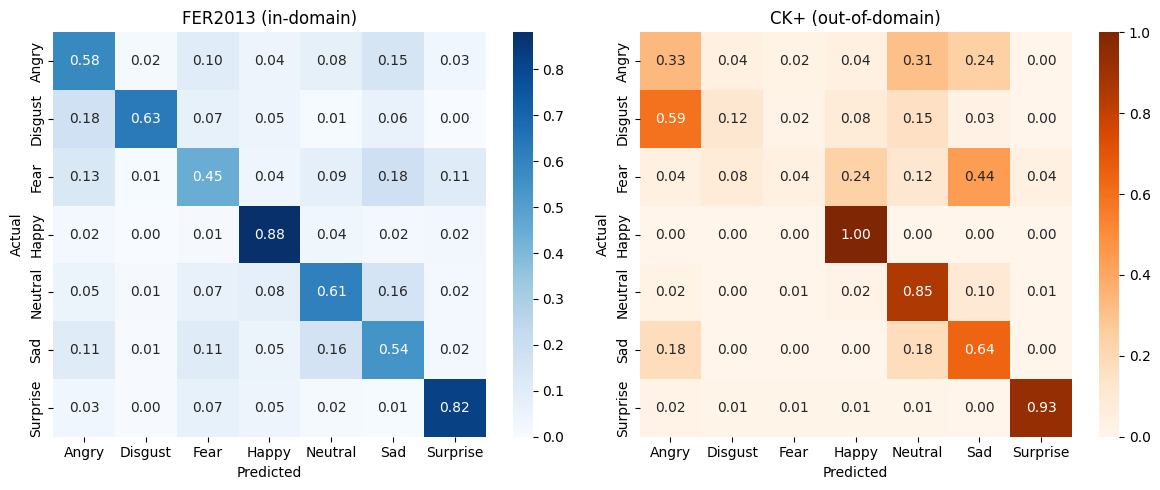

In [5]:
"""
================================================================================
PHASE 5 (FACE MODEL): CROSS-DATASET TESTING ON CK+ (CSV format)
================================================================================
CK+ (davilsena/ckdataset) ships as ckextended.csv with columns:
  emotion (0-7), pixels (48x48 space-separated grayscale values), Usage
Emotion codes: 0=Angry, 1=Disgust, 2=Fear, 3=Happy, 4=Sad, 5=Surprise,
               6=Neutral, 7=Contempt (no FER2013 equivalent - skipped)

CK+ is LAB-CONTROLLED (posed expressions, clean lighting, frontal faces) -
very different conditions from FER2013's web-scraped "in the wild" images.
Expect a real generalization gap here; that's an informative result, not a bug.

PREREQUISITES: run after Phase 4 in the same session (needs multi_model,
predict_single_image(), class_names, get_all_predictions equivalent for FER2013,
IMG_SIZE, vgg16_preprocess, resnet_preprocess, inception_preprocess).
================================================================================
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

CKPLUS_CSV_PATH = "/kaggle/input/datasets/davilsena/ckdataset/ckextended.csv"  # <-- confirm exact path from left panel

EMOTION_CODE_TO_NAME = {
    0: "Angry", 1: "Disgust", 2: "Fear", 3: "Happy",
    4: "Sad", 5: "Surprise", 6: "Neutral", 7: "Contempt",
}


def load_ckplus(path):
    df = pd.read_csv(path)
    print(f"Loaded {len(df)} rows. Usage split:\n{df['Usage'].value_counts()}")
    df["emotion_name"] = df["emotion"].map(EMOTION_CODE_TO_NAME)

    n_contempt = (df["emotion_name"] == "Contempt").sum()
    df = df[df["emotion_name"] != "Contempt"].reset_index(drop=True)
    print(f"Dropped {n_contempt} 'Contempt' rows (no FER2013 equivalent).")
    print(f"Usable rows: {len(df)}\nClass distribution:\n{df['emotion_name'].value_counts()}")
    return df


def pixels_to_pil_image(pixel_string):
    arr = np.array(pixel_string.split(), dtype=np.uint8).reshape(48, 48)
    return Image.fromarray(arr, mode="L")


def evaluate_ckplus(model, df):
    y_true_names, y_pred_names, confidences = [], [], []
    for _, row in df.iterrows():
        img = pixels_to_pil_image(row["pixels"])
        pred_cls, conf = predict_single_image(model, img)
        y_true_names.append(row["emotion_name"])
        y_pred_names.append(pred_cls)
        confidences.append(conf)

    df = df.copy()
    df["pred"] = y_pred_names
    df["confidence"] = confidences

    y_true = np.array(y_true_names)
    y_pred = np.array(y_pred_names)

    acc = accuracy_score(y_true, y_pred)
    used_classes = sorted(df["emotion_name"].unique())
    mf1 = f1_score(y_true, y_pred, labels=used_classes, average="macro", zero_division=0)

    print(f"\n{'='*70}\nResults on CK+ (n={len(df)})\n{'='*70}")
    print(f"Accuracy: {acc*100:.2f}% | Macro F1: {mf1*100:.2f}%")
    print(f"Avg confidence: {df['confidence'].mean()*100:.1f}%")
    print(f"\n(Report covers classes present in CK+: {used_classes})")
    print(classification_report(y_true, y_pred, labels=used_classes, zero_division=0))

    return df, y_true, y_pred, used_classes, acc, mf1


def compare_with_fer2013(y_true_ck, y_pred_ck, used_classes, ck_acc, ck_mf1):
    # in-domain reference from Phase 4's true FER2013 test set
    raw_test_ds, true_test_data = build_true_test_pipeline()
    fer_pred, fer_true_idx, fer_probs = get_all_predictions(multi_model, true_test_data)
    fer_true_names = np.array([class_names[i] for i in fer_true_idx])
    fer_pred_names = np.array([class_names[i] for i in fer_pred])

    mask = np.isin(fer_true_names, used_classes)
    fer_acc = accuracy_score(fer_true_names[mask], fer_pred_names[mask])
    fer_mf1 = f1_score(fer_true_names[mask], fer_pred_names[mask], labels=used_classes,
                        average="macro", zero_division=0)

    gap_acc = (fer_acc - ck_acc) * 100
    print(f"\n{'='*70}\nGENERALIZATION GAP: FER2013 (in-domain) vs CK+ (out-of-domain)\n{'='*70}")
    comp = pd.DataFrame({
        "Metric": ["Accuracy", "Macro F1"],
        "FER2013 (in-domain)": [f"{fer_acc*100:.2f}%", f"{fer_mf1*100:.2f}%"],
        "CK+ (out-of-domain)": [f"{ck_acc*100:.2f}%", f"{ck_mf1*100:.2f}%"],
        "Gap (points)": [f"{gap_acc:.2f}", f"{(fer_mf1-ck_mf1)*100:.2f}"],
    })
    print(comp.to_string(index=False))

    if gap_acc < -10:
        note = ("CK+ accuracy is HIGHER than FER2013 - expected, since CK+ has "
                 "posed/peak expressions in clean lab conditions, which are easier "
                 "than FER2013's noisy web-scraped images.")
    elif abs(gap_acc) <= 10:
        note = "Comparable performance - model generalizes reasonably across conditions."
    else:
        note = "Notable drop on CK+ despite it being 'easier' lab data - worth investigating."
    print(f"\nNote: {note}")

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    cm_fer = confusion_matrix(fer_true_names[mask], fer_pred_names[mask], labels=used_classes, normalize="true")
    cm_ck = confusion_matrix(y_true_ck, y_pred_ck, labels=used_classes, normalize="true")
    sns.heatmap(cm_fer, annot=True, fmt=".2f", cmap="Blues", xticklabels=used_classes, yticklabels=used_classes, ax=axes[0])
    axes[0].set_title("FER2013 (in-domain)")
    sns.heatmap(cm_ck, annot=True, fmt=".2f", cmap="Oranges", xticklabels=used_classes, yticklabels=used_classes, ax=axes[1])
    axes[1].set_title("CK+ (out-of-domain)")
    for ax in axes:
        ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    plt.tight_layout()
    plt.show()


if __name__ == "__main__":
    df = load_ckplus(CKPLUS_CSV_PATH)
    df, y_true, y_pred, used_classes, acc, mf1 = evaluate_ckplus(multi_model, df)
    compare_with_fer2013(y_true, y_pred, used_classes, acc, mf1)


In [6]:
"""
================================================================================
PHASE 7: LATENCY FIX - TFLite Conversion + Quantization
================================================================================
Your model takes ~140ms per single-image prediction (Phase 4 Section D) - too
slow for real-time video (30fps needs <33ms budget). This converts the model
to TFLite with quantization, which is dramatically faster for inference,
and benchmarks the speed/accuracy trade-off so you can decide what's acceptable.

PREREQUISITES: run after loading your model (MODEL_PATH, multi_model available),
and ideally after Phase 4 (needs build_true_test_pipeline, predict_single_image,
class_names, IMG_SIZE, vgg16_preprocess, resnet_preprocess, inception_preprocess).
================================================================================
"""

import os
import time
import numpy as np
import tensorflow as tf
from sklearn.metrics import accuracy_score

MODEL_TO_CONVERT = MODEL_PATH  # path to your .keras file


# --------------------------------------------------------------------------------
# 1. Convert to TFLite - three variants to compare
# --------------------------------------------------------------------------------

def convert_to_tflite(keras_model_path, output_path, quantization="none"):
    model = tf.keras.models.load_model(keras_model_path)
    converter = tf.lite.TFLiteConverter.from_keras_model(model)

    if quantization == "dynamic_range":
        converter.optimizations = [tf.lite.Optimize.DEFAULT]
    elif quantization == "float16":
        converter.optimizations = [tf.lite.Optimize.DEFAULT]
        converter.target_spec.supported_types = [tf.float16]
    # "none" = no quantization, just format conversion

    tflite_model = converter.convert()
    with open(output_path, "wb") as f:
        f.write(tflite_model)

    size_mb = os.path.getsize(output_path) / (1024 * 1024)
    print(f"Saved {output_path} ({size_mb:.1f} MB, quantization={quantization})")
    return output_path


print("Converting model to TFLite (this can take a few minutes for 3 backbones)...")
path_fp32 = convert_to_tflite(MODEL_TO_CONVERT, "/kaggle/working/model_fp32.tflite", "none")
path_dynamic = convert_to_tflite(MODEL_TO_CONVERT, "/kaggle/working/model_dynamic_quant.tflite", "dynamic_range")
path_fp16 = convert_to_tflite(MODEL_TO_CONVERT, "/kaggle/working/model_fp16.tflite", "float16")


# --------------------------------------------------------------------------------
# 2. Load a TFLite model as an inference-ready interpreter
# --------------------------------------------------------------------------------

def load_tflite_interpreter(tflite_path):
    interpreter = tf.lite.Interpreter(model_path=tflite_path)
    interpreter.allocate_tensors()
    return interpreter


def predict_tflite(interpreter, pil_img):
    """Runs one PIL image through a TFLite interpreter (multi-input model)."""
    input_details = interpreter.get_input_details()
    output_details = interpreter.get_output_details()

    img = pil_img.convert("L").resize((48, 48))
    arr = np.array(img)[..., None].astype(np.float32)
    rgb = tf.image.grayscale_to_rgb(tf.constant(arr)[None, ...])
    resized = tf.image.resize(rgb, IMG_SIZE, method="bicubic")
    branch_inputs = {
        "vgg": vgg16_preprocess(resized).numpy(),
        "resnet": resnet_preprocess(resized).numpy(),
        "inception": inception_preprocess(resized).numpy(),
    }

    # match tflite input order by tensor name hints (vgg/resnet/inception) -
    # falls back to positional order if names don't contain hints
    name_matched = all(any(k in d["name"].lower() for k in ["vgg", "resnet", "inception"]) for d in input_details)
    if name_matched:
        for detail in input_details:
            name = detail["name"].lower()
            if "vgg" in name:
                interpreter.set_tensor(detail["index"], branch_inputs["vgg"])
            elif "resnet" in name:
                interpreter.set_tensor(detail["index"], branch_inputs["resnet"])
            elif "inception" in name:
                interpreter.set_tensor(detail["index"], branch_inputs["inception"])
    else:
        for detail, arr_in in zip(input_details, [branch_inputs["vgg"], branch_inputs["resnet"], branch_inputs["inception"]]):
            interpreter.set_tensor(detail["index"], arr_in)

    interpreter.invoke()
    probs = interpreter.get_tensor(output_details[0]["index"])[0]
    pred = int(np.argmax(probs))
    return class_names[pred], float(probs[pred])


# --------------------------------------------------------------------------------
# 3. Benchmark latency for each variant
# --------------------------------------------------------------------------------

def benchmark_tflite(tflite_path, sample_img, n_runs=30):
    interpreter = load_tflite_interpreter(tflite_path)
    _ = predict_tflite(interpreter, sample_img)  # warm-up

    times = []
    for _ in range(n_runs):
        t0 = time.time()
        _ = predict_tflite(interpreter, sample_img)
        times.append((time.time() - t0) * 1000)
    times = np.array(times)
    print(f"  mean: {times.mean():.1f} ms | p50: {np.percentile(times,50):.1f} ms | "
          f"p95: {np.percentile(times,95):.1f} ms")
    return times.mean()


# --------------------------------------------------------------------------------
# 4. Accuracy check - make sure quantization didn't break predictions
# --------------------------------------------------------------------------------

def accuracy_check_tflite(tflite_path, raw_test_ds, n_samples=200):
    interpreter = load_tflite_interpreter(tflite_path)
    file_paths = raw_test_ds.file_paths
    sample_paths = np.random.RandomState(42).choice(file_paths, size=min(n_samples, len(file_paths)), replace=False)

    correct = 0
    for p in sample_paths:
        from PIL import Image
        folder_name = os.path.basename(os.path.dirname(p)).lower()
        true_cls = next((c for c in class_names if c.lower() == folder_name), folder_name)
        img = Image.open(p)
        pred_cls, _ = predict_tflite(interpreter, img)
        correct += (pred_cls == true_cls)
    return correct / len(sample_paths)


# --------------------------------------------------------------------------------
# RUN COMPARISON
# --------------------------------------------------------------------------------

from PIL import Image

_, true_test_data = build_true_test_pipeline()
raw_test_ds, _ = build_true_test_pipeline()
sample_img = Image.open(raw_test_ds.file_paths[0])

print(f"\n{'='*70}\nLATENCY COMPARISON\n{'='*70}")
print("Original .keras model (baseline from Phase 4): ~140 ms mean\n")

print("FP32 TFLite (no quantization):")
lat_fp32 = benchmark_tflite(path_fp32, sample_img)

print("\nDynamic-range quantized TFLite:")
lat_dynamic = benchmark_tflite(path_dynamic, sample_img)

print("\nFloat16 quantized TFLite:")
lat_fp16 = benchmark_tflite(path_fp16, sample_img)

print(f"\n{'='*70}\nACCURACY COMPARISON (n=200 sample, on true test set)\n{'='*70}")
print("Checking each variant hasn't lost meaningful accuracy vs the original model...")
acc_fp32 = accuracy_check_tflite(path_fp32, raw_test_ds)
acc_dynamic = accuracy_check_tflite(path_dynamic, raw_test_ds)
acc_fp16 = accuracy_check_tflite(path_fp16, raw_test_ds)

print(f"\n{'Variant':<25}{'Latency (ms)':<15}{'Accuracy':<12}")
print(f"{'FP32 TFLite':<25}{lat_fp32:<15.1f}{acc_fp32*100:<12.1f}")
print(f"{'Dynamic-range quant':<25}{lat_dynamic:<15.1f}{acc_dynamic*100:<12.1f}")
print(f"{'Float16 quant':<25}{lat_fp16:<15.1f}{acc_fp16*100:<12.1f}")

print("\nRecommendation: dynamic-range quantization usually gives the best "
      "speed/accuracy trade-off for CPU deployment (e.g. a Flask/FastAPI server "
      "without GPU). Float16 keeps accuracy closest to the original but is "
      "mainly faster on GPU/specialized hardware, not standard CPU. Pick "
      "whichever variant meets your latency budget with an accuracy drop you "
      "can live with.")


Converting model to TFLite (this can take a few minutes for 3 backbones)...
INFO:tensorflow:Assets written to: /tmp/tmpdtfsly8b/assets


INFO:tensorflow:Assets written to: /tmp/tmpdtfsly8b/assets


Saved artifact at '/tmp/tmpdtfsly8b'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): List[TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_vgg16'), TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_resnet50'), TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_inceptionv3')]
Output Type:
  TensorSpec(shape=(None, 7), dtype=tf.float32, name=None)
Captures:
  140496156518032: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140496156519568: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140496156517840: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140496156517648: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140496156519184: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140496156520336: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140496156516880: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140496156518800: TensorSpec(shape=(), dtype=tf.resource,

W0000 00:00:1789844342.363470      23 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1789844342.363522      23 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1789844342.849164      23 mlir_graph_optimization_pass.cc:437] MLIR V1 optimization pass is not enabled


Saved /kaggle/working/model_fp32.tflite (238.4 MB, quantization=none)
INFO:tensorflow:Assets written to: /tmp/tmpkqttpurn/assets


INFO:tensorflow:Assets written to: /tmp/tmpkqttpurn/assets


... (5 outputs left out)

W0000 00:00:1789844435.633601      23 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1789844435.633641      23 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.


Saved /kaggle/working/model_fp16.tflite (119.3 MB, quantization=float16)
Found 7178 files belonging to 7 classes.
Found 7178 files belonging to 7 classes.

LATENCY COMPARISON
Original .keras model (baseline from Phase 4): ~140 ms mean

FP32 TFLite (no quantization):


/usr/local/lib/python3.12/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


  mean: 541.3 ms | p50: 536.8 ms | p95: 568.8 ms

Dynamic-range quantized TFLite:
  mean: 616.4 ms | p50: 615.3 ms | p95: 630.6 ms

Float16 quantized TFLite:
  mean: 542.4 ms | p50: 541.1 ms | p95: 561.7 ms

ACCURACY COMPARISON (n=200 sample, on true test set)
Checking each variant hasn't lost meaningful accuracy vs the original model...

Variant                  Latency (ms)   Accuracy    
FP32 TFLite              541.3          68.0        
Dynamic-range quant      616.4          64.0        
Float16 quant            542.4          69.0        

Recommendation: dynamic-range quantization usually gives the best speed/accuracy trade-off for CPU deployment (e.g. a Flask/FastAPI server without GPU). Float16 keeps accuracy closest to the original but is mainly faster on GPU/specialized hardware, not standard CPU. Pick whichever variant meets your latency budget with an accuracy drop you can live with.
